[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch13-concepts_workbook.ipynb)

# Three chains, each right 0.4 of the time

A model writes three chains of thought for one question with two possible
answers, and each chain is right with probability 0.4. A majority vote keeps
the answer that two or three chains give. Does the vote beat one chain? The
lecture's numbers answer it, together with the posterior over tasks, the
cosine choice of demonstrations and the bill a prompt runs up.

In [1]:
#@title Setup: run this cell first
import math

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# The lecture's stylised values: the input and three candidate demonstrations as vectors, and the bill's rate in dollars
# per 1,000 input tokens and its queries a day.
CANDIDATES = {"a": (1, 0, 0), "b": (0, 1, 2), "c": (1, 2, 0)}
RATE, QUERIES = 0.10, 100_000
plt.rcParams.update({"xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8})


class Refused(Exception):  # a setting a cell refuses: Colab prints the one sentence, without the stack
    _render_traceback_ = lambda self: [str(self)]  # noqa: E731


def number(name, x, lo, hi):  # a number typed in a cell
    if type(x) not in (int, float) or not lo <= x <= hi:
        show = lambda v: f"{v:,}" if v == int(v) else f"{v:g}"  # noqa: E731
        raise Refused(f"{name} is {x!r}: {name} takes a number from {show(lo)} to {show(hi)}.")
    return x


def whole(name, x, lo, hi):  # a whole number typed in a cell
    if type(x) is not int or not lo <= x <= hi:
        raise Refused(f"{name} is {x!r}: {name} takes a whole number from {lo:,} to {hi:,}.")
    return x


# Step 1: every demonstration multiplies the odds on task T by RATIO, and the posterior is odds / (1 + odds).
def posteriors(prior, ratio, k):
    odds = number("PRIOR", prior, 0.001, 0.999) / (1 - prior)
    number("RATIO", ratio, 0.01, 100)
    return [odds * ratio ** j / (1 + odds * ratio ** j) for j in range(whole("DEMONSTRATIONS", k, 0, 20) + 1)]


def show_posterior(prior, ratio, k):
    ps = posteriors(prior, ratio, k)
    print("posterior on T after " + ", ".join(f"{j}: {x:.2f}" for j, x in enumerate(ps)))
    fig, ax = plt.subplots(figsize=(6, 3), layout="constrained")
    b = ax.bar(range(len(ps)), ps, color=["0.6"] + ["C0"] * k)
    ax.bar_label(b, fmt="%.2f", padding=2, fontsize=8)
    ax.set(title=f"prior {prior:g}, each demonstration {ratio:g} times likelier under T", ylim=(0, 1.12),
           xlabel="demonstrations in the prompt", ylabel="posterior on task T", xticks=list(range(len(ps))))
    plt.show()


# Step 2: KATE keeps the K_KEEP candidates with the highest cosine similarity to the input.
def cosine(u, v):
    return sum(a * b for a, b in zip(u, v)) / math.sqrt(sum(a * a for a in u) * sum(b * b for b in v))


def cosines(q):
    if type(q) is not tuple or len(q) != 3 or any(type(x) not in (int, float) or abs(x) > 1000 for x in q) or not any(q):
        raise Refused(f"Q is {q!r}: Q takes three numbers from -1,000 to 1,000, not all 0, as in (2, 1, 0).")
    return {name: cosine(q, v) for name, v in CANDIDATES.items()}


def show_cosines(q, keep):
    cos = cosines(q)
    kept = sorted(cos, key=lambda n: -cos[n])[:whole("K_KEEP", keep, 1, 3)]
    print("cosines " + ", ".join(f"{n} {c:.2f}" for n, c in cos.items()) + f"; kept {', '.join(kept)}; last: {kept[0]}")
    fig, ax = plt.subplots(figsize=(6, 2.2), layout="constrained")
    b = ax.barh(list(cos), list(cos.values()), color=["C3" if n in kept else "0.6" for n in cos])
    ax.bar_label(b, fmt="%.2f", padding=2, fontsize=8)
    ax.set(title=f"cosine of each candidate with the input {q}, kept in red", xlim=(min(0, *cos.values()) - 0.05, 1.25),
           ylim=(2.6, -0.6))
    plt.show()


# Step 3: K independent chains, two possible answers, each right with probability p. The vote is right when more than
# half are right; at an even K a tie counts as a loss.
def majority(p, k):
    return sum(math.comb(k, j) * p ** j * (1 - p) ** (k - j) for j in range(k // 2 + 1, k + 1))


def show_votes(p):
    ks = range(1, 41)
    acc = [majority(number("P", p, 0, 1), k) for k in ks]
    print(f"p {p:g}: one chain {acc[0]:.3f}, three {acc[2]:.3f}, five {acc[4]:.3f}, forty {acc[39]:.3f}")
    fig, ax = plt.subplots(figsize=(6, 3), layout="constrained")
    ax.plot(ks[::2], acc[::2], "o-", ms=3, color="C3", label=f"odd K at p {p:g}")
    ax.plot(ks[1::2], acc[1::2], "o", ms=3, color="0.6", label="even K, a tie a loss")
    ax.axhline(p, color="0.5", ls="--", label="one chain")
    ax.set(title="majority accuracy against the number of chains", xlabel="chains K", ylabel="accuracy", ylim=(-0.03, 1.03))
    ax.legend()
    plt.show()


# Appendix: a query sends the whole prompt, so a day costs tokens x queries / 1,000 x RATE dollars, and a vote over
# CALLS chains sends it CALLS times.
def bill(tokens, calls=1):
    return whole("TOKENS", tokens, 1, 10 ** 6) * QUERIES / 1000 * RATE * whole("CALLS", calls, 1, 100)


def show_bill(lengths):
    days = [bill(t) for t in lengths]
    fig, ax = plt.subplots(figsize=(6, 2.2), layout="constrained")
    b = ax.barh([f"{t:,} tokens" for t in lengths], days, color=["0.6"] * (len(lengths) - 1) + ["C3"])
    ax.bar_label(b, labels=[f"{d:,.0f} dollars a day" for d in days], padding=2, fontsize=8)
    ax.set(title=f"{QUERIES:,} queries a day at {RATE:.2f} dollars per 1,000 input tokens", xlim=(0, 1.6 * max(days)),
           ylim=(len(lengths) - 0.4, -0.6))
    plt.show()

## 1. The posterior over two tasks

Read in-context learning as inference over a latent task. Two tasks start
at a prior of 0.5 each, and every demonstration is three times as likely
under task T as under the other task. Each demonstration multiplies the
odds on T by 3, and the posterior is the odds over one plus the odds. Run
the cell. Then set `RATIO` to 2: what is the posterior after two
demonstrations?

posterior on T after 0: 0.50, 1: 0.75, 2: 0.90, 3: 0.96


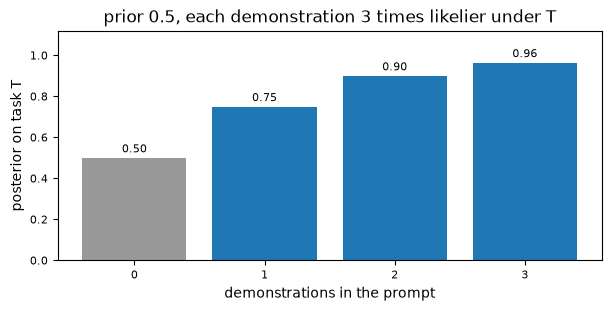

In [2]:
PRIOR = 0.5
RATIO = 3
DEMONSTRATIONS = 3
show_posterior(PRIOR, RATIO, DEMONSTRATIONS)

### Solution

In [3]:
ps, two = posteriors(0.5, 3, 3), posteriors(0.5, 2, 2)
display(Markdown(f"After 0, 1, 2 and 3 demonstrations the posterior is {ps[0]:.2f}, {ps[1]:.2f}, {ps[2]:.2f} and "
                 f"{ps[3]:.2f}: the first demonstration adds {ps[1] - ps[0]:.2f}, the second {ps[2] - ps[1]:.2f} and the "
                 f"third {ps[3] - ps[2]:.2f}. At a ratio of 2, two demonstrations give odds of {2 * 2} and a posterior of "
                 f"{two[2]:.2f}. The weights never change; only the evidence in the prompt does."))

After 0, 1, 2 and 3 demonstrations the posterior is 0.50, 0.75, 0.90 and 0.96: the first demonstration adds 0.25, the second 0.15 and the third 0.06. At a ratio of 2, two demonstrations give odds of 4 and a posterior of 0.80. The weights never change; only the evidence in the prompt does.

## 2. The demonstration nearest the input

KATE embeds the input and every candidate demonstration with one sentence
encoder and keeps the k candidates with the highest cosine similarity to the
input. The lecture's input is `(2, 1, 0)`, its candidates a, b and c. Run the
cell, which keeps two. Then set `Q` to `(0, 1, 1)` and `K_KEEP` to 1: which
candidate does KATE keep, and at what cosine?

cosines a 0.89, b 0.20, c 0.80; kept a, c; last: a


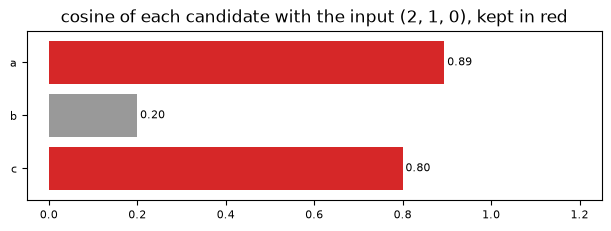

In [4]:
Q = (2, 1, 0)
K_KEEP = 2
show_cosines(Q, K_KEEP)

### Solution

In [5]:
first, second = cosines((2, 1, 0)), cosines((0, 1, 1))
display(Markdown(f"For the input (2, 1, 0) the cosines are a {first['a']:.2f}, b {first['b']:.2f} and c "
                 f"{first['c']:.2f}, so KATE keeps a and c, and a, the most similar, goes last, immediately before the input. "
                 f"For (0, 1, 1) they are a {second['a']:.2f}, b {second['b']:.2f} and c {second['c']:.2f}, and keeping one "
                 f"keeps b."))

For the input (2, 1, 0) the cosines are a 0.89, b 0.20 and c 0.80, so KATE keeps a and c, and a, the most similar, goes last, immediately before the input. For (0, 1, 1) they are a 0.00, b 0.95 and c 0.63, and keeping one keeps b.

## 3. A majority vote over chains

Sample K chains of thought for one question with two possible answers. If
the chains are independent and each is right with probability p, the vote
is right when more than half of them are right, and a tie counts as a loss.
Run the cell for p 0.4, the chains of the puzzle. Then set `P` to 0.6: what
does the vote do as K grows?

p 0.4: one chain 0.400, three 0.352, five 0.317, forty 0.074


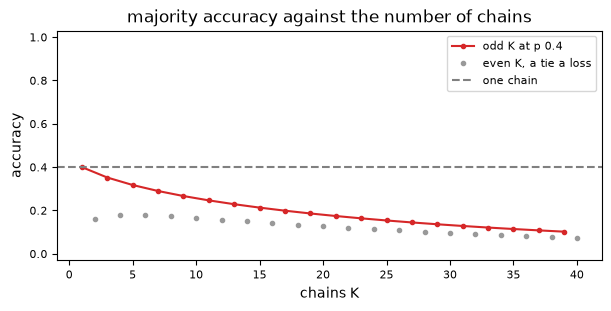

In [6]:
P = 0.4
show_votes(P)

### Solution

In [7]:
display(Markdown(f"At p 0.4 three chains vote right {majority(0.4, 3):.3f} of the time, below one chain's 0.4, and 40 chains "
                 f"{100 * majority(0.4, 40):.1f} per cent: no, the vote does not beat one chain here. It moves away from 0.5 on "
                 f"the side the chains fall. At p 0.6 three chains give {majority(0.6, 3):.3f} and 40 chains "
                 f"{100 * majority(0.6, 40):.1f} per cent. A tie loses, so 10 chains at 0.6 give "
                 f"{100 * majority(0.6, 10):.1f} per cent, below the {100 * majority(0.6, 5):.1f} of 5 chains."))

At p 0.4 three chains vote right 0.352 of the time, below one chain's 0.4, and 40 chains 7.4 per cent: no, the vote does not beat one chain here. It moves away from 0.5 on the side the chains fall. At p 0.6 three chains give 0.648 and 40 chains 87.0 per cent. A tie loses, so 10 chains at 0.6 give 63.3 per cent, below the 68.3 of 5 chains.

## Appendix. The daily bill

Every query sends the whole prompt, so the bill per query is the prompt's
length in tokens times the rate. The cell compares prompts of 100, 500 and
2,000 tokens at 0.10 dollars per 1,000 input tokens and 100,000 queries a
day.

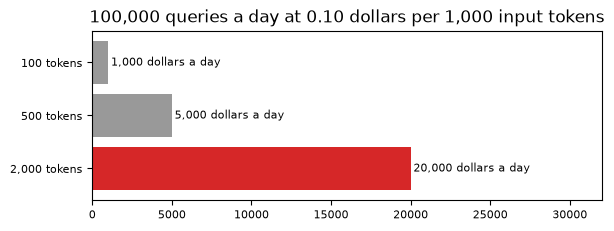

In [8]:
show_bill([100, 500, 2000])

**Exercise.** Set `TOKENS` to 800: what does that prompt cost a day? Then
set `CALLS` to 40, a vote over 40 chains with one call each.

In [9]:
TOKENS = 100
CALLS = 1
print(f"{TOKENS:,} tokens, {CALLS} call(s) a query: {bill(TOKENS, CALLS):,.0f} dollars a day")

100 tokens, 1 call(s) a query: 1,000 dollars a day


### Solution

In [10]:
display(Markdown(f"An 800-token prompt costs {bill(800):,.0f} dollars a day, against {bill(100):,.0f} at 100 tokens and "
                 f"{bill(2000):,.0f} at 2,000. A vote over 40 chains sends it 40 times: {bill(800, 40):,.0f} dollars a day."))

An 800-token prompt costs 8,000 dollars a day, against 1,000 at 100 tokens and 20,000 at 2,000. A vote over 40 chains sends it 40 times: 320,000 dollars a day.